# MiniChefGPT with Qwen3-0.6B LoRA fine-tuning

Fine-tune **Qwen/Qwen3-0.6B**, a 600M-parameter chat model, on the same `recipe_10000.csv`, cleaning, and train/validation/test split as the MiniChefGPT and GPT-2 notebooks. The base model stays frozen; small **LoRA** adapter matrices learn the recipe task.

**Where it runs**
- **This computer (CPU):** the base model is loaded in normal 32-bit precision and LoRA trains within a time budget. About 8 seconds per recipe here, so a 60-minute budget covers roughly 450 recipes.
- **NVIDIA GPU (Colab, Kaggle):** the base model is loaded in 4-bit (QLoRA) when `bitsandbytes` is installed. Clone the repository first so the data and helper modules are available: `!git clone https://github.com/Annemarie535257/MiniChefGPT` then `%cd MiniChefGPT`.

**Output:** the best adapter is saved to its own folder, `models/qwen3/adapter/` (about 40 MB, with the tokenizer). It is not a standalone model; loading it also downloads the base model from Hugging Face. Results go to `models/qwen3/`.

Run from the project root after `python -m pip install -r requirements.txt`. The first run downloads Qwen3-0.6B (about 1.5 GB).

## 1. Settings

The learning rate warms up, then follows a cosine decay over the **time budget**, so the schedule completes even when the budget ends training before `MAX_STEPS`. One step is one optimizer update over `BATCH_SIZE × GRAD_ACCUM` recipes. Set `TRAIN_MODEL = False` to reuse the saved adapter.

In [1]:
import gc
import importlib.util
import json
import math
import os
import random
import time

import matplotlib.pyplot as plt
import pandas as pd
import torch
from torch.nn import functional as F
import transformers
from transformers import AutoModelForCausalLM, AutoTokenizer
from peft import LoraConfig, get_peft_model

import minichefgpt as chef
import qwen3_recipes as qr

transformers.logging.set_verbosity_error()
transformers.utils.logging.disable_progress_bar()

PROJECT_ROOT = chef.PROJECT_ROOT
MODEL_NAME = qr.BASE_MODEL
OUTPUT_DIR = PROJECT_ROOT / 'models' / 'qwen3'
ADAPTER_DIR = OUTPUT_DIR / 'adapter'

TRAIN_MODEL = True
SEED = 42
MAX_LENGTH = 320           # tokens per example, prompt included; longer recipes are truncated
TRAINING_MINUTES = 60      # 0 disables the time budget
MAX_STEPS = 1000
LEARNING_RATE = 2e-4
MIN_LR_RATIO = 0.1
WARMUP_STEPS = 5
WEIGHT_DECAY = 0.0
LORA_R, LORA_ALPHA, LORA_DROPOUT = 16, 32, 0.05
LORA_TARGETS = ['q_proj', 'k_proj', 'v_proj', 'o_proj', 'gate_proj', 'up_proj', 'down_proj']
EVAL_EVERY_MINUTES = 12
TEST_RECIPES = None        # None scores every test recipe
CUSTOM_CANDIDATES = 8      # drafts per custom input, as in the other notebooks
GENERATION_TOKENS = 320
CPU_THREADS = max(1, (os.cpu_count() or 2) - 2)

USE_CUDA = torch.cuda.is_available()
USE_4BIT = USE_CUDA and importlib.util.find_spec('bitsandbytes') is not None
if USE_CUDA:
    BATCH_SIZE, GRAD_ACCUM, EVAL_RECIPES, EVAL_BATCH = 4, 4, 120, 8
    GRADIENT_CHECKPOINTING = True
else:
    # CPU: small micro-batches keep memory near 4 GB; accumulation gives 8 recipes per update.
    BATCH_SIZE, GRAD_ACCUM, EVAL_RECIPES, EVAL_BATCH = 2, 4, 40, 4
    GRADIENT_CHECKPOINTING = False

chef.seed_everything(SEED)
torch.set_num_threads(CPU_THREADS)
device = torch.device('cuda' if USE_CUDA else 'cpu')
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
mode = 'QLoRA (4-bit base)' if USE_4BIT else ('LoRA (16/32-bit base)' if USE_CUDA else 'LoRA (32-bit base on CPU)')
print(f'Device: {torch.cuda.get_device_name(0) if USE_CUDA else "CPU"} | {mode} | threads {torch.get_num_threads()} '
      f'| recipes per update {BATCH_SIZE * GRAD_ACCUM} | transformers {transformers.__version__}')

Device: CPU | LoRA (32-bit base on CPU) | threads 10 | recipes per update 8 | transformers 5.21.0


## 2. Recipe data

Reuse the original cleaning and seeded title-group split from `minichefgpt.py`, so the test recipes are exactly the unseen recipes the other two models were evaluated on.

In [2]:
rows = chef.load_recipes()
splits = chef.split_recipes(rows, seed=SEED)
for name in ('train', 'validation', 'test'):
    print(f'{name}: {len(splits[name]):,} recipes ({len(splits[name]) / len(rows):.1%})')
titles = {name: {row['title'] for row in values} for name, values in splits.items()}
assert titles['train'].isdisjoint(titles['validation']) and titles['train'].isdisjoint(titles['test'])
assert titles['validation'].isdisjoint(titles['test'])
print('No recipe title appears in more than one split.')

Read 10,000 rows; kept 9,979 recipes from recipe_10000.csv.
Recipe split: {'train': 8983, 'validation': 502, 'test': 494}
train: 8,983 recipes (90.0%)
validation: 502 recipes (5.0%)
test: 494 recipes (5.0%)
No recipe title appears in more than one split.


## 3. Qwen3 chat format and tokens

The user message lists the ingredients; the assistant answers with `Title:` and numbered `Steps:`. Qwen3's thinking mode is turned off (`enable_thinking=False`). The prompt functions live in `qwen3_recipes.py`, so the app uses exactly the same format. Only the answer tokens and the closing `<|im_end|>` token count toward the loss.

In [3]:
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
tokenizer.padding_side = 'right'
END_ID = tokenizer.convert_tokens_to_ids('<|im_end|>')
example = splits['train'][0]
print(qr.prompt_text(tokenizer, example['ingredients']) + qr.assistant_answer(example) + '<|im_end|>')


def encode_recipe(row):
    prompt = tokenizer(qr.prompt_text(tokenizer, row['ingredients']), add_special_tokens=False).input_ids
    response = tokenizer(qr.assistant_answer(row), add_special_tokens=False).input_ids + [END_ID]
    if len(prompt) >= MAX_LENGTH - 8:
        return None
    ids = (prompt + response)[:MAX_LENGTH]
    labels = ([chef.IGNORE_INDEX] * len(prompt) + response)[:MAX_LENGTH]
    return ids, labels, len(prompt) + len(response) > MAX_LENGTH


encoded, truncated, skipped = {}, {}, {}
for name, values in splits.items():
    items = [encode_recipe(row) for row in values]
    encoded[name] = [(ids, labels) for item in items if item for ids, labels, _ in [item]]
    truncated[name] = sum(item[2] for item in items if item)
    skipped[name] = sum(item is None for item in items)
print('\nEncoded:', {name: len(values) for name, values in encoded.items()})
print(f'Truncated to {MAX_LENGTH} tokens:', truncated, '| prompt too long (skipped):', skipped)


def make_batch(examples):
    length = max(len(ids) for ids, _ in examples)
    input_ids = torch.full((len(examples), length), tokenizer.pad_token_id, dtype=torch.long)
    labels = torch.full_like(input_ids, chef.IGNORE_INDEX)
    attention_mask = torch.zeros_like(input_ids)
    for row, (ids, target) in enumerate(examples):
        input_ids[row, :len(ids)] = torch.tensor(ids)
        labels[row, :len(target)] = torch.tensor(target)
        attention_mask[row, :len(ids)] = 1
    return input_ids.to(device), labels.to(device), attention_mask.to(device)


def training_batches(examples, batch_size, seed):
    """Group similar lengths to reduce padding, and shuffle batch order every epoch."""
    rng = random.Random(seed)
    epoch = 0
    while True:
        order = sorted(range(len(examples)), key=lambda i: (len(examples[i][0]), rng.random()))
        batches = [order[i:i + batch_size] for i in range(0, len(order), batch_size)]
        rng.shuffle(batches)
        for batch in batches:
            yield epoch, [examples[i] for i in batch]
        epoch += 1


def batch_loss(model, batch):
    """Summed next-token loss over answer tokens.

    Qwen3 has a 151,936-token vocabulary, so the output layer runs only at answer positions
    instead of producing logits for every prompt and padding token.
    """
    input_ids, labels, attention_mask = batch
    lm = model.get_base_model() if hasattr(model, 'get_base_model') else model
    hidden = lm.model(input_ids=input_ids, attention_mask=attention_mask).last_hidden_state[:, :-1]
    targets = labels[:, 1:]
    valid = targets != chef.IGNORE_INDEX
    logits = lm.lm_head(hidden[valid]).float()
    return F.cross_entropy(logits, targets[valid], reduction='sum'), valid.sum()


@torch.inference_mode()
def response_loss(model, examples, batch_size=EVAL_BATCH):
    was_training = model.training
    model.eval()
    total, count = 0.0, 0
    order = sorted(range(len(examples)), key=lambda i: len(examples[i][0]))
    for start in range(0, len(order), batch_size):
        loss_sum, tokens = batch_loss(model, make_batch([examples[i] for i in order[start:start + batch_size]]))
        total += loss_sum.item()
        count += tokens.item()
    model.train(was_training)
    return {'loss': total / count, 'perplexity': math.exp(total / count), 'tokens': count}


eval_examples = random.Random(SEED).sample(encoded['validation'], min(EVAL_RECIPES, len(encoded['validation'])))

<|im_start|>system
You are MiniChefGPT, a home cooking assistant. Write one sensible recipe that uses the given ingredients, with a short title and numbered steps.<|im_end|>
<|im_start|>user
Create a recipe using these ingredients: water, butter, all-purpose flour, eggs, cream cheese, milk, instant vanilla pudding, cool whip<|im_end|>
<|im_start|>assistant
<think>

</think>

Title: cream puff cake
Steps:
1. preheat oven to 400 degrees.
2. in a large heavy suacepan, heat butter and water to boiling over medium-high heat.
3. add flour and reduce heat to low.
4. cook and stir until it forms a ball and pulls away from the sides of the pan.
5. remove from heat and transfer to a large bowl.
6. beat in eggs, one at a time, beating well after each egg.
7. spread in bottom and up the sides of an ungreased 9x13 inch pan.
8. bake at 400 degrees for 35 minutes.
9. cool completely.
10. to make the filling: in a large bowl, combine cream cheese and milk and beat until smooth.
11. add pudding mix and

## 4. Load Qwen3 and attach LoRA adapters

Only the LoRA matrices train, about 10M of 606M parameters. On a GPU with `bitsandbytes`, the frozen base is stored in 4-bit; on a CPU it stays in 32-bit, which needs about 2.5 GB of memory.

In [4]:
if USE_4BIT:
    from transformers import BitsAndBytesConfig
    from peft import prepare_model_for_kbit_training
    compute_dtype = torch.bfloat16 if torch.cuda.is_bf16_supported() else torch.float16
    base = AutoModelForCausalLM.from_pretrained(
        MODEL_NAME, device_map={'': 0}, dtype=compute_dtype,
        quantization_config=BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_quant_type='nf4',
                                               bnb_4bit_use_double_quant=True, bnb_4bit_compute_dtype=compute_dtype))
    base = prepare_model_for_kbit_training(base, use_gradient_checkpointing=GRADIENT_CHECKPOINTING)
else:
    dtype = torch.bfloat16 if USE_CUDA and torch.cuda.is_bf16_supported() else torch.float32
    base = AutoModelForCausalLM.from_pretrained(MODEL_NAME, dtype=dtype).to(device)
    if GRADIENT_CHECKPOINTING:
        base.gradient_checkpointing_enable(gradient_checkpointing_kwargs={'use_reentrant': False})
base.config.use_cache = False
model = get_peft_model(base, LoraConfig(r=LORA_R, lora_alpha=LORA_ALPHA, lora_dropout=LORA_DROPOUT, bias='none',
                                        task_type='CAUSAL_LM', target_modules=LORA_TARGETS))
model.print_trainable_parameters()

trainable params: 10,092,544 || all params: 606,142,464 || trainable%: 1.6650


## 5. Qwen3 before fine-tuning

With the adapter switched off, measure the untouched chat model on the validation subset and ask it for one recipe. This is the starting point that fine-tuning improves on.

In [5]:
with model.disable_adapter():
    pretrained_validation = response_loss(model, eval_examples)
    print(f"Qwen3 before fine-tuning | validation subset loss {pretrained_validation['loss']:.4f} "
          f"| perplexity {pretrained_validation['perplexity']:.2f}\n")
    before = qr.generate_qwen3_recipe(model, tokenizer, chef.CUSTOM_INGREDIENTS['Chicken dinner'],
                                      candidates=1, seed=SEED, max_new_tokens=GENERATION_TOKENS)
chef.print_recipe(before)

Qwen3 before fine-tuning | validation subset loss 2.7281 | perplexity 15.30

Title: Chicken Garlic Onion Tomato Stir Fry
Ingredients: chicken, garlic, onion, tomato
1. Heat a pan and add some oil.
2. Add chicken and sauté until golden.
3. Add garlic and onion.
4. Add tomato and stir until the mixture is well mixed.
5. Serve hot.
Ingredient mentions: 100% | EOS: True


## 6. Fine-tune

Train with AdamW, warmup, time-based cosine decay, and gradient clipping. Every few minutes the fixed validation subset is scored, and the best adapter is saved to `models/qwen3/adapter/`.

In [6]:
def learning_rate(step, elapsed):
    if step <= WARMUP_STEPS:
        return LEARNING_RATE * step / WARMUP_STEPS
    progress = step / MAX_STEPS
    if TRAINING_MINUTES > 0:
        progress = max(progress, elapsed / (TRAINING_MINUTES * 60))
    progress = min(1.0, progress)
    minimum = LEARNING_RATE * MIN_LR_RATIO
    return minimum + 0.5 * (LEARNING_RATE - minimum) * (1 + math.cos(math.pi * progress))


def save_adapter(model):
    model.save_pretrained(ADAPTER_DIR)
    tokenizer.save_pretrained(ADAPTER_DIR)


def fine_tune(model):
    trainable = [p for p in model.parameters() if p.requires_grad]
    optimizer = torch.optim.AdamW(trainable, lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
    batches = training_batches(encoded['train'], BATCH_SIZE, SEED)
    history, best_loss = [], math.inf
    start = last_report = last_eval = time.monotonic()
    running_loss, running_tokens, stop_reason = 0.0, 0, 'max_steps'
    for step in range(1, MAX_STEPS + 1):
        model.train()
        lr = learning_rate(step, time.monotonic() - start)
        for group in optimizer.param_groups:
            group['lr'] = lr
        micro = [next(batches) for _ in range(GRAD_ACCUM)]
        epoch = micro[-1][0]
        batches_here = [make_batch(examples) for _, examples in micro]
        # Normalize by every answer token in the update, not per micro-batch.
        total_tokens = sum(int((labels[:, 1:] != chef.IGNORE_INDEX).sum()) for _, labels, _ in batches_here)
        optimizer.zero_grad(set_to_none=True)
        step_loss = 0.0
        for batch in batches_here:
            loss_sum, _ = batch_loss(model, batch)
            if not torch.isfinite(loss_sum):
                raise FloatingPointError('Non-finite training loss')
            (loss_sum / total_tokens).backward()
            step_loss += loss_sum.item()
        torch.nn.utils.clip_grad_norm_(trainable, 1.0)
        optimizer.step()
        running_loss += step_loss
        running_tokens += total_tokens
        now = time.monotonic()
        budget_reached = TRAINING_MINUTES > 0 and now - start >= TRAINING_MINUTES * 60
        if step == 1 or now - last_report >= 60:
            print(f'Step {step:4d} | epoch {epoch} | loss {step_loss / total_tokens:.3f} | lr {lr:.1e} '
                  f'| {(now - start) / 60:.1f} min', flush=True)
            last_report = now
        if budget_reached or step == MAX_STEPS or now - last_eval >= EVAL_EVERY_MINUTES * 60:
            validation = response_loss(model, eval_examples)
            history.append({'step': step, 'epoch': epoch, 'recipes_seen': step * BATCH_SIZE * GRAD_ACCUM,
                            'train_loss': running_loss / running_tokens,
                            'validation_loss': validation['loss'], 'validation_perplexity': validation['perplexity'],
                            'learning_rate': lr, 'elapsed_seconds': time.monotonic() - start})
            running_loss, running_tokens = 0.0, 0
            message = f"Validation subset | step {step} | loss {validation['loss']:.4f} | perplexity {validation['perplexity']:.2f}"
            if validation['loss'] < best_loss:
                best_loss = validation['loss']
                save_adapter(model)
                message += ' | saved'
            print(message, flush=True)
            (OUTPUT_DIR / 'training_history.json').write_text(json.dumps(history, indent=2), encoding='utf-8')
            last_eval = time.monotonic()
        if budget_reached:
            stop_reason = 'time_budget'
            break
    run = {'steps': step, 'recipes_seen': step * BATCH_SIZE * GRAD_ACCUM, 'stop_reason': stop_reason,
           'elapsed_seconds': time.monotonic() - start, 'best_validation_subset_loss': best_loss, 'mode': mode}
    print('Finished:', run)
    return history, run


if TRAIN_MODEL:
    history, run = fine_tune(model)
    (OUTPUT_DIR / 'run.json').write_text(json.dumps(run, indent=2), encoding='utf-8')
else:
    history = json.loads((OUTPUT_DIR / 'training_history.json').read_text(encoding='utf-8'))
    run = json.loads((OUTPUT_DIR / 'run.json').read_text(encoding='utf-8'))
print('Saved adapter:', ADAPTER_DIR, sorted(p.name for p in ADAPTER_DIR.iterdir()))

Step    1 | epoch 0 | loss 3.142 | lr 4.0e-05 | 3.8 min
Step    2 | epoch 0 | loss 2.876 | lr 8.0e-05 | 6.4 min
Step    4 | epoch 0 | loss 2.374 | lr 1.6e-04 | 8.2 min
Step    6 | epoch 0 | loss 2.150 | lr 1.9e-04 | 9.7 min
Step    8 | epoch 0 | loss 2.207 | lr 1.9e-04 | 11.6 min
Step    9 | epoch 0 | loss 2.146 | lr 1.8e-04 | 12.8 min


C:\Users\Hp\AppData\Local\Python\pythoncore-3.11-64\Lib\site-packages\peft\utils\save_and_load.py:313: UserWarning: Could not find a config file in Qwen/Qwen3-0.6B - will assume that the vocabulary was not modified.
  warnings.warn(


Validation subset | step 9 | loss 2.0383 | perplexity 7.68 | saved
Step   10 | epoch 0 | loss 2.050 | lr 1.8e-04 | 15.7 min
Step   12 | epoch 0 | loss 2.148 | lr 1.7e-04 | 17.3 min
Step   14 | epoch 0 | loss 1.972 | lr 1.6e-04 | 18.7 min
Step   16 | epoch 0 | loss 2.077 | lr 1.6e-04 | 20.5 min
Step   18 | epoch 0 | loss 2.028 | lr 1.5e-04 | 22.3 min
Step   20 | epoch 0 | loss 2.139 | lr 1.4e-04 | 24.4 min
Step   21 | epoch 0 | loss 1.865 | lr 1.4e-04 | 25.7 min
Step   22 | epoch 0 | loss 1.820 | lr 1.3e-04 | 26.8 min
Validation subset | step 22 | loss 1.9399 | perplexity 6.96 | saved
Step   23 | epoch 0 | loss 1.909 | lr 1.1e-04 | 34.3 min
Step   24 | epoch 0 | loss 2.126 | lr 9.0e-05 | 39.0 min
Step   25 | epoch 0 | loss 1.766 | lr 6.9e-05 | 42.5 min
Step   26 | epoch 0 | loss 2.121 | lr 5.5e-05 | 46.3 min
Validation subset | step 26 | loss 1.9272 | perplexity 6.87 | saved
Step   27 | epoch 0 | loss 1.928 | lr 2.5e-05 | 57.8 min
Step   28 | epoch 0 | loss 2.360 | lr 2.1e-05 | 60.3 min

## 7. Test the saved adapter

Free the training model, then load the base model plus the saved adapter from disk exactly as the app does (`qwen3_recipes.load_qwen3`, which merges the adapter for faster inference). Score the validation subset and every test answer token.

These losses use Qwen3's tokenizer, so they are comparable with Qwen3 before fine-tuning but **not** with GPT-2 or MiniChefGPT. The generation comparison below uses the same inputs and score for all three models.

In [7]:
del model, base
gc.collect()
if USE_CUDA:
    torch.cuda.empty_cache()
model, tokenizer = qr.load_qwen3(ADAPTER_DIR, device=device)
validation = response_loss(model, eval_examples)
test_examples = encoded['test'] if TEST_RECIPES is None else encoded['test'][:TEST_RECIPES]
test = response_loss(model, test_examples)
summary = pd.DataFrame([
    {'model': 'Qwen3 before fine-tuning', 'split': 'validation subset', **pretrained_validation},
    {'model': 'Qwen3 fine-tuned', 'split': 'validation subset', **validation},
    {'model': 'Qwen3 fine-tuned', 'split': 'test', **test},
])
print(summary.to_string(index=False))

                   model             split     loss  perplexity  tokens
Qwen3 before fine-tuning validation subset 2.728103   15.303834    5605
        Qwen3 fine-tuned validation subset 1.925627    6.859448    5605
        Qwen3 fine-tuned              test 1.982721    7.262476   65357


## 8. Compare MiniChefGPT, GPT-2, and Qwen3

Generate recipes for the four custom ingredient lists (best of 8 drafts) and for the same 12 unseen test recipes used for the other models (1 draft each), with the same seeds and the same `ingredient_coverage` score. Earlier outputs are read from `models/refactored/` and `models/gpt2/`.

In [8]:
def read_results(folder):
    try:
        heldout = json.loads((folder / 'heldout_generation.json').read_text(encoding='utf-8'))
        custom = json.loads((folder / 'custom_recipes.json').read_text(encoding='utf-8'))
        return heldout, custom
    except OSError:
        return None, None


def benchmark(outputs):
    return {'ingredient_mentions': sum(r['ingredient_coverage'] for r in outputs) / len(outputs),
            'end_marker_rate': sum(r['finished'] for r in outputs) / len(outputs),
            'nonempty_steps_rate': sum(bool(r['steps']) for r in outputs) / len(outputs),
            'mean_steps': sum(len(r['steps']) for r in outputs) / len(outputs)}


original_heldout, original_custom = read_results(PROJECT_ROOT / 'models' / 'refactored')
gpt2_heldout, gpt2_custom = read_results(PROJECT_ROOT / 'models' / 'gpt2')

custom = {}
for index, (name, ingredients) in enumerate(chef.CUSTOM_INGREDIENTS.items()):
    print('\n' + name, flush=True)
    custom[name] = qr.generate_qwen3_recipe(model, tokenizer, ingredients, candidates=CUSTOM_CANDIDATES,
                                            seed=SEED + 10 * index, max_new_tokens=GENERATION_TOKENS)
    chef.print_recipe(custom[name])

test_rows = {row['id']: row for row in splits['test']}
heldout = []
for index, original in enumerate(original_heldout):
    row = test_rows[original['recipe_id']]
    recipe = qr.generate_qwen3_recipe(model, tokenizer, row['ingredients'], candidates=1,
                                      seed=SEED + index, max_new_tokens=GENERATION_TOKENS)
    heldout.append({'recipe_id': row['id'], 'reference_title': row['title'], **recipe})

table = {'MiniChefGPT, 12 unseen': benchmark(original_heldout)}
if gpt2_heldout:
    table['GPT-2, 12 unseen'] = benchmark(gpt2_heldout)
table['Qwen3, 12 unseen'] = benchmark(heldout)
table['MiniChefGPT, 4 custom'] = benchmark(list(original_custom.values()))
if gpt2_custom:
    table['GPT-2, 4 custom'] = benchmark(list(gpt2_custom.values()))
table['Qwen3, 4 custom'] = benchmark(list(custom.values()))
comparison = pd.DataFrame(table).T
print()
print(comparison.round(3).to_string())

print('\nUnseen test recipes: reference title | MiniChefGPT | GPT-2 | Qwen3 (ingredient mentions)')
gpt2_titles = gpt2_heldout or [None] * len(heldout)
for original, gpt2, new in zip(original_heldout, gpt2_titles, heldout):
    gpt2_text = f"{gpt2['title']} ({gpt2['ingredient_coverage']:.0%})" if gpt2 else '—'
    print(f"- {new['reference_title']} | {original['title']} ({original['ingredient_coverage']:.0%})"
          f" | {gpt2_text} | {new['title']} ({new['ingredient_coverage']:.0%})")

metrics = {'model': MODEL_NAME, 'adapter': (ADAPTER_DIR.relative_to(PROJECT_ROOT).as_posix() if ADAPTER_DIR.is_relative_to(PROJECT_ROOT)
                       else str(ADAPTER_DIR)), 'run': run,
           'pretrained_validation_subset': pretrained_validation, 'validation_subset': validation, 'test': test,
           'truncated_recipes': truncated,
           'settings': {'max_length': MAX_LENGTH, 'batch_size': BATCH_SIZE, 'grad_accum': GRAD_ACCUM,
                        'learning_rate': LEARNING_RATE, 'lora_r': LORA_R, 'lora_alpha': LORA_ALPHA,
                        'training_minutes': TRAINING_MINUTES, 'max_steps': MAX_STEPS, 'seed': SEED},
           'heldout_benchmark': benchmark(heldout), 'custom_benchmark': benchmark(list(custom.values())),
           'quality_note': 'Ingredient mentions do not measure recipe correctness. Inspect the drafts.'}
(OUTPUT_DIR / 'metrics.json').write_text(json.dumps(metrics, indent=2), encoding='utf-8')
(OUTPUT_DIR / 'custom_recipes.json').write_text(json.dumps(custom, indent=2), encoding='utf-8')
(OUTPUT_DIR / 'heldout_generation.json').write_text(json.dumps(heldout, indent=2), encoding='utf-8')


Chicken dinner
Title: chicken tomato
Ingredients: chicken, garlic, onion, tomato
1. preheat oven to 400f.
2. in a large bowl, combine the chicken, garlic, and onion.
3. add the tomato and the remaining ingredients and mix well.
4. bake for 10-15 minutes, or until the chicken is browned and the tomato is tender.
5. let cool and serve.
Ingredient mentions: 100% | EOS: True

Vegetable pasta
Title: tomato basil pasta
Ingredients: pasta, tomato, garlic, basil
1. heat a large pan of water and bring to a boil.
2. add the pasta and cook for 3-4 minutes or until al dente.
3. drain the pasta and add the tomato, garlic and basil.
4. toss until the tomatoes and herbs are well coated.
5. serve with a small portion of olive oil and lemon juice over the pasta.
6. sprinkle with salt and pepper if you like.
Ingredient mentions: 100% | EOS: True

Cheese omelet
Title: spinach and cheese casserole
Ingredients: eggs, cheese, onion, spinach
1. preheat oven to 350 degrees f.
2. in a large bowl, mix together

## 9. Training curve

Training loss is the average over the updates since the previous check; validation loss uses the fixed validation subset.

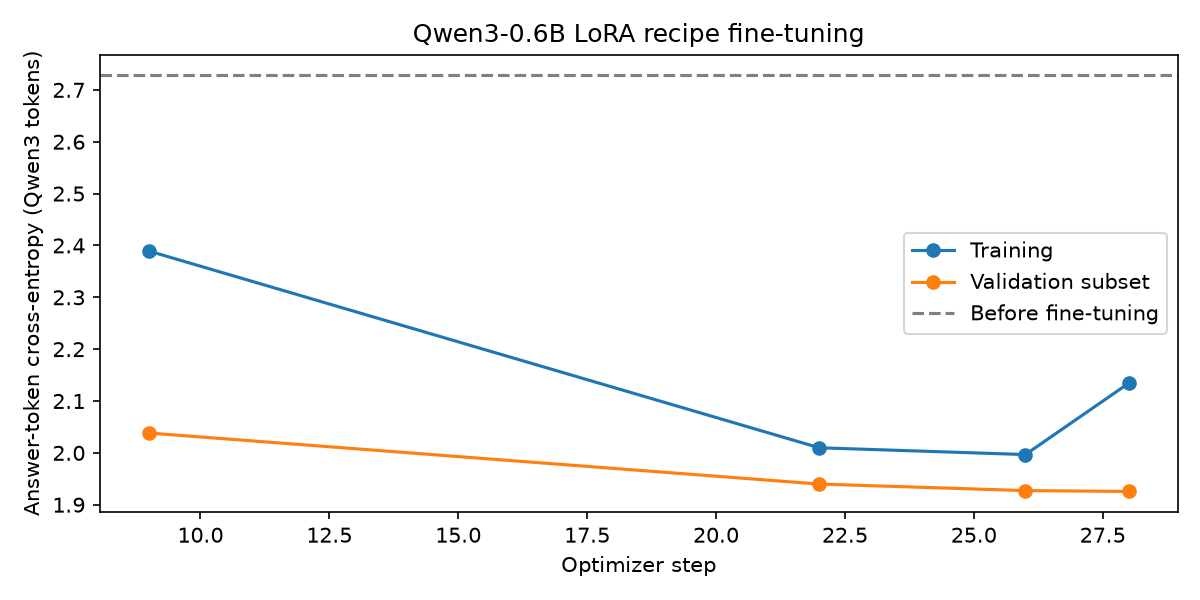

In [9]:
plot_data = pd.DataFrame(history)
plt.figure(figsize=(8, 4))
plt.plot(plot_data['step'], plot_data['train_loss'], marker='o', label='Training')
plt.plot(plot_data['step'], plot_data['validation_loss'], marker='o', label='Validation subset')
plt.axhline(pretrained_validation['loss'], color='gray', linestyle='--', label='Before fine-tuning')
plt.xlabel('Optimizer step')
plt.ylabel('Answer-token cross-entropy (Qwen3 tokens)')
plt.title('Qwen3-0.6B LoRA recipe fine-tuning')
plt.legend()
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'training_loss.png', dpi=150)
plt.show()
plt.close()

## 10. Your ingredients

Edit the list and rerun this cell. It uses the adapter loaded from disk in section 7. In a new session, load it with `model, tokenizer = qr.load_qwen3(ADAPTER_DIR)` instead of retraining.

In [10]:
my_ingredients = ['chicken', 'garlic', 'onion', 'tomato']
my_recipe = qr.generate_qwen3_recipe(model, tokenizer, my_ingredients, seed=123, max_new_tokens=GENERATION_TOKENS)
chef.print_recipe(my_recipe)

Title: chicken and tomato soup
Ingredients: chicken, garlic, onion, tomato
1. in a large pot, sauté the garlic and onion in a little oil until softened.
2. add the chicken and cook until done.
3. add the tomato and the soup stock, cover and simmer for 10 minutes.
4. serve with rice or crusty bread.
Ingredient mentions: 100% | EOS: True


## Notes on deployment and quality

- The adapter in `models/qwen3/adapter/` is small enough for a normal git push. It is **not** a standalone model: `qwen3_recipes.load_qwen3` downloads `Qwen/Qwen3-0.6B` from Hugging Face and applies it.
- On a CPU the merged model uses about 2.5 GB of memory, which can exceed small hosting plans such as Streamlit Community Cloud.
- The app imports the same prompt from `qwen3_recipes.py`, with thinking turned off, so training and inference cannot drift apart.
- Ingredient mentions do not prove cooking correctness. Review food safety, allergies, and dietary needs before relying on any recipe.
- References: [Qwen3-0.6B](https://huggingface.co/Qwen/Qwen3-0.6B) and [PEFT](https://huggingface.co/docs/peft/).